# BERT und Stellenkategorien – Übung

**Geschäftliches Problem:** Einem Stellenanzeigen-Portal bei der Auswahl einer Stellenkategorie helfen, indem eine Kategorie oder eine Auswahlliste mit drei Kategorien vorgeschlagen wird.

Wir verwenden die echten Stellenanzeigen, die der Seite 37 der NLP-Vorlesung aus Woche 08 zugrunde liegen. Ein Modell unterstützt die Entscheidung bei der Überprüfung; es trifft die geschäftliche Entscheidung nicht für uns.

## Lernziele

- Eine Textrepräsentation mit den Baseline-Modellen auf Basis von Worthäufigkeiten und TF-IDF vergleichen.
- Das Training (Fitting), die Modellauswahl anhand der Validierungsdaten und die abschliessende Evaluation voneinander trennen.
- Fehler und Einschränkungen interpretieren, bevor ein geschäftlicher Einsatz vorgeschlagen wird.

## Datensatz und praktischer Umfang

Die bereitgestellte Datei `nlp_real_job_categories.csv.gz` enthält **5'011 echte, bereinigte und anonymisierte Stellenbeschreibungen aus 143 Kategorien** und keine künstlich erzeugten Beispiele. Es handelt sich um genau den Datensatz für die Klassifikation, der der Seite 37 von `Slides_MSC_Data_Science_Week_08_EN.pdf` zugrunde liegt.

- **Training:** 3'328 Stellenanzeigen aus Juli und August 2026; 139 Kategorien.
- **Validierung:** 918 Stellenanzeigen vom 1. bis 14. September; 118 Kategorien.
- **Test:** 765 Stellenanzeigen ab dem 15. September; 114 Kategorien.

Die ursprüngliche Stichprobe mit 30'000 Stellenanzeigen wurde so gefiltert, dass jede Anzeige genau einer `JOBS:`-Kategorie zugeordnet ist. Widersprüchliche Kategorienzuordnungen und später auftretende, exakt identische Stellenbeschreibungen wurden entfernt. Die Datenbereinigung und die chronologische Aufteilung sind bereits vorgegeben. Deshalb konzentrieren wir uns auf die Modellierung, anstatt die Datenaufbereitung zu wiederholen. IDs und Datumsangaben werden nicht als Modellmerkmale verwendet.

Einige Kategorien, die in späteren Zeiträumen vorkommen, fehlen in den Trainingsdaten: **Drei Validierungsanzeigen und zwei Testanzeigen** besitzen Kategorien, die das Modell beim Training noch nicht gesehen hat. Behalte diese Anzeigen in der Evaluation. Ein Klassifikator kann keine Kategorie vorschlagen, die er nie gelernt hat. Das Entfernen exakt identischer Duplikate beseitigt nicht alle beinahe identischen Anzeigen oder Vorlagen. Es handelt sich um einen bereits untersuchten Lehrdatensatz und nicht um einen vollständig unbeeinflussten Forschungs-Testdatensatz.

Die Lehrperson hat bestätigt, dass dieser Teil des Klassifikationsdatensatzes für die Zielgruppe des Repositories verwendet werden darf. Die Anonymisierung garantiert jedoch keine vollständige Anonymität. Gehe deshalb nicht davon aus, dass die Daten uneingeschränkt weiterverbreitet werden dürfen. Siehe [Datenhinweise](../../../00_Data/nlp_data_readme.md).

Führe das Notebook von oben nach unten aus. Die vollständige Merkmalsextraktion ist Teil der praktischen Arbeit und kein zusätzlicher Vorlesungsabschnitt.

Vervollständige die beiden markierten Code-Lücken, bevor du die entsprechenden Zellen ausführst.

## Bibliotheken und Einstellungen

Verwende den vorbereiteten Python-3.11-Kernel im Codespace. Es wird weder eine GPU noch ein API-Schlüssel benötigt.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

SEED = 7
np.random.seed(SEED)
DATA_ROOT = Path('../../../00_Data')

## 1. Minimale Dateninspektion

Pandas liest die komprimierte CSV-Datei direkt ein. Behalte die vorgegebenen chronologischen Datenaufteilungen bei. Wir untersuchen die Anzahl der Einträge und die Datumsbereiche, anstatt die vollständigen Stellenbeschreibungen auszugeben.

In [2]:
jobs = pd.read_csv(DATA_ROOT / 'nlp_real_job_categories.csv.gz',
                   parse_dates=['creation_date'])
required = {'teaching_id', 'creation_date', 'text', 'category', 'split'}
if not required.issubset(jobs.columns) or jobs[list(required)].isna().any().any():
    raise ValueError('Missing columns or values in the prepared real job ads.')
if not jobs['split'].isin(['train', 'validation', 'test']).all():
    raise ValueError('Unexpected partition name.')
if not jobs['teaching_id'].is_unique or jobs['text'].str.casefold().duplicated().any():
    raise ValueError('Repeated IDs or cleaned descriptions in the prepared data.')
parts = {name: jobs[jobs['split'] == name].copy()
         for name in ['train', 'validation', 'test']}
if any(frame.empty for frame in parts.values()):
    raise ValueError('Every partition needs ads.')
if not (parts['train']['creation_date'].max() < parts['validation']['creation_date'].min()
        <= parts['validation']['creation_date'].max() < parts['test']['creation_date'].min()):
    raise ValueError('The chronological partitions overlap or are out of order.')
training_categories = set(parts['train']['category'])
display(pd.DataFrame([
    {'split': name, 'ads': len(frame), 'categories': frame['category'].nunique(),
     'first date': frame['creation_date'].min().date(),
     'last date': frame['creation_date'].max().date(),
     'ads with unseen category': (~frame['category'].isin(training_categories)).sum()}
    for name, frame in parts.items()
]))
display(parts['train']['category'].value_counts().head(10).rename('training ads').to_frame())

,split,ads,categories,first date,last date,ads with unseen category
0,train,3328,139,2026-07-01,2026-08-31,0
1,validation,918,118,2026-09-01,2026-09-14,3
2,test,765,114,2026-09-15,2026-09-28,2


,training ads
category,
SALES_RETAIL_TRADE,221
NURSING,169
GERIATRICS,114
LOGISTICS_SUPPLY_CHAIN,113
MANUFACTURING_PRODUCTION_INDUSTRY,111
REAL_ESTATE_MANAGEMENT_TRADE,78
CIVIL_ENGINEERING_SUPERVISION,78
STORAGE,77
CNC_MECHANICS_POLYMECHANICS,76


## 2. Geschäftliches und statistisches Baseline-Modell

Ein Baseline-Modell auf Basis von Häufigkeiten ignoriert den Text und schlägt die häufigsten Kategorien aus den Trainingsdaten vor. TF-IDF in Kombination mit logistischer Regression dient als lexikalisches Baseline-Modell. Das Vokabular und die IDF-Werte werden ausschliesslich anhand der Trainingsanzeigen bestimmt. Zuvor wird die weiter unten beschriebene BERT-Tokenisierung durchgeführt, damit beide trainierten Klassifikatoren dieselben beibehaltenen Eingabetexte verwenden.

Die bereitgestellte Evaluationsfunktion gibt Accuracy (Genauigkeit), Macro-F1 und die Top-3-Trefferquote aus. Macro-F1 bildet den Durchschnitt über die Kategorien, die tatsächlich im jeweils evaluierten Datensatz vorkommen. Kategorien, die nur vorhergesagt werden, aber im evaluierten Datensatz nicht vorkommen, werden nicht zusätzlich in diesen Durchschnitt aufgenommen.

Wenn eine TF-IDF-Zeile keine bekannten Begriffe enthält, soll eine manuelle Überprüfung angefordert und die Vorhersage als Fehlversuch gezählt werden, anstatt stillschweigend einen Vorschlag zu verwenden, der ausschliesslich auf dem Intercept (Achsenabschnitt) des Modells basiert.

In [3]:
import re
from sklearn.dummy import DummyClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

y_train = parts['train']['category'].to_numpy()
y_validation = parts['validation']['category'].to_numpy()
y_test = parts['test']['category'].to_numpy()
prior = DummyClassifier(strategy='prior', random_state=SEED).fit(
    np.ones((len(y_train), 1)), y_train)

TOKEN_PATTERN = re.compile(r"[^\W\d_]+(?:['\u2019-][^\W\d_]+)*", re.UNICODE)

def tokenize(text):
    return [word for word in TOKEN_PATTERN.findall(text) if len(word) > 1]

tfidf = TfidfVectorizer(
    tokenizer=tokenize, token_pattern=None, min_df=3, max_features=20_000,
    sublinear_tf=True, dtype=np.float32)

def evaluate_suggestions(labels, probabilities, classes, covered):
    if probabilities.shape != (len(labels), len(classes)) or covered.shape != (len(labels),):
        raise ValueError('Predictions, labels and coverage have incompatible shapes.')
    if not np.isfinite(probabilities).all() or not np.allclose(probabilities.sum(axis=1), 1):
        raise ValueError('Expected finite classifier probabilities summing to one.')
    ranking = np.argsort(-probabilities, axis=1, kind='stable')
    predicted = np.where(covered, classes[ranking[:, 0]], '__REVIEW__')
    top3 = classes[ranking[:, :3]]
    hits = (top3 == labels[:, None]).any(axis=1) & covered
    metrics = {
        'accuracy': accuracy_score(labels, predicted),
        'macro-F1': f1_score(labels, predicted, labels=np.unique(labels),
                             average='macro', zero_division=0),
        'top-3 hit rate': hits.mean(),
        'top-3 hits': int(hits.sum()),
        'review only': int((~covered).sum()),
    }
    return metrics, predicted, top3

## 3. Einen vortrainierten Encoder wiederverwenden

Bei der ersten Verwendung werden die öffentlich verfügbaren BERT-Dateien heruntergeladen (ca. 700 MB). Die Stellenbeschreibungen werden lokal verarbeitet und nicht an eine Vorhersage-API gesendet. Die Parameter von BERT bleiben unverändert: Nur der später eingesetzte Klassifikator für die Stellenkategorien lernt anhand unserer Kategorienzuordnungen. Lade die Modellgewichte vor dem Unterricht herunter.

Wir verwenden dasselbe festgelegte mehrsprachige BERT-Modell mit Unterscheidung zwischen Gross- und Kleinschreibung wie in der Vorlesung. Jede Stellenanzeige wird auf **126 Text-Token plus zwei spezielle BERT-Markierungen** begrenzt. TF-IDF erhält eine aus denselben Token rekonstruierte Textversion und nicht die vollständige Stellenbeschreibung. Dadurch bleiben die verwendeten Eingabetexte vergleichbar, auch wenn sich durch die Rekonstruktion die Formatierung verändert.

Die nächste Codezelle zeigt, wie viele Stellenbeschreibungen aufgrund dieser Begrenzung gekürzt wurden.

In [4]:
import torch
from transformers import AutoTokenizer, AutoModelForMaskedLM

torch.manual_seed(SEED)
torch.set_num_threads(2)
torch.use_deterministic_algorithms(True)
MODEL = 'google-bert/bert-base-multilingual-cased'
REVISION = '3f076fdb1ab68d5b2880cb87a0886f315b8146f8'
tokenizer = AutoTokenizer.from_pretrained(MODEL, revision=REVISION)
encoder = AutoModelForMaskedLM.from_pretrained(
    MODEL, revision=REVISION, use_safetensors=True).eval()
encoder.requires_grad_(False)
if tokenizer.do_lower_case:
    raise ValueError('This example requires the cased multilingual checkpoint.')
print('Frozen encoder; pooled values per document:', encoder.config.hidden_size)

/home/vscode/.local/lib/python3.11/site-packages/huggingface_hub/file_download.py:1132: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(


tokenizer_config.json:   0%|          | 0.00/49.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/625 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/714M [00:00<?, ?B/s]

Some weights of the model checkpoint at google-bert/bert-base-multilingual-cased were not used when initializing BertForMaskedLM: ['bert.pooler.dense.bias', 'bert.pooler.dense.weight', 'cls.seq_relationship.bias', 'cls.seq_relationship.weight']
- This IS expected if you are initializing BertForMaskedLM from the checkpoint of a model trained on another task or with another architecture (e.g. initializing a BertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing BertForMaskedLM from the checkpoint of a model that you expect to be exactly identical (initializing a BertForSequenceClassification model from a BertForSequenceClassification model).


Frozen encoder; pooled values per document: 768


## 4. Kontextabhängige Token-Merkmale zusammenfassen (Pooling)

BERT gibt jedem Token (einem Wort oder Wortbestandteil) einen Vektor mit **768 Zahlen**. Jeder Vektor hängt vom umgebenden Text ab. Unser Klassifikator für Stellenkategorien benötigt jedoch **einen Vektor mit fester Länge pro Stellenanzeige**, auch wenn die Anzeigen unterschiedlich lang sind.

**Pooling bedeutet, diese Token-Vektoren zu einem einzigen Vektor für die Stellenanzeige zusammenzufassen.** Hier berechnen wir einfach den Durchschnitt, und zwar für jede Koordinate einzeln. Beispielsweise ergeben 80 Text-Token insgesamt 80 Vektoren. Wenn wir deren Durchschnitt berechnen, erhalten wir einen einzigen Vektor mit 768 Zahlen und nicht einen Vektor mit 80 Zahlen.

Ein kleines, frei erfundenes Beispiel mit nur drei Zahlen pro Token:

| Token | Vektor |
|---|---|
| software | [1, 2, 0] |
| engineer | [3, 0, 2] |
| wanted | [2, 1, 1] |
| **Durchschnitt für die Stellenanzeige** | **[2, 1, 1]** |

**Programmieraufgabe:** Berechne diesen Durchschnitt in der Zeile `pooled` im folgenden Code:

- `hidden` enthält die Token-Vektoren von BERT.
- `content` markiert echte Text-Token mit 1 und Auffüllpositionen (Padding) oder spezielle Markierungen mit 0. Durch die Multiplikation mit `content` werden diese zusätzlichen Positionen ausgeschlossen.
- Summiere über die Token-Positionen (`dim=1`) und teile anschliessend durch `content.sum(dim=1)`, also die Anzahl der Text-Token.

`Stellenanzeige -> BERT-Token-Vektoren -> Durchschnitt -> Anzeigenvektor mit 768 Zahlen -> Klassifikator -> Kategorievorschläge\`

**Dieser Schritt trainiert BERT nicht und sagt noch keine Kategorie voraus.** Er bereitet lediglich die Eingabedaten für den Klassifikator vor, den wir als Nächstes trainieren. Die von BERT erzeugten Zahlen bleiben unverändert, auch wenn wir die Validierungs- und Testanzeigen verarbeiten. TF-IDF und die Skalierung lernen ihre Parameter weiterhin ausschliesslich aus den Trainingsdaten. Der Code zeigt den Fortschritt während der Verarbeitung der einzelnen Datensätze an.

**Einschränkungen:** Durch die Durchschnittsbildung gehen Details auf Token-Ebene verloren. Ausserdem verwenden wir nur die ersten **126 Text-Token** jeder Stellenanzeige. Dadurch können wichtige Anforderungen gegen Ende der Beschreibung fehlen. Der resultierende Vektor fasst deshalb nicht unbedingt die gesamte Stellenbeschreibung zusammen.

In [6]:
def encode_ads(texts):
    rows, retained = [], []
    truncated = 0
    for start in range(0, len(texts), 8):
        examples = list(texts[start:start + 8])
        truncated += sum(len(tokenizer.tokenize(text, verbose=False)) > 126
                         for text in examples)
        batch = tokenizer(examples, padding=True, truncation=True, max_length=128,
                          return_tensors='pt', return_special_tokens_mask=True)
        special = batch.pop('special_tokens_mask')
        content = (batch['attention_mask'] * (1 - special)).unsqueeze(-1)
        if torch.any(content.sum(dim=1) == 0):
            raise ValueError('An ad has no content tokens after tokenization.')
        with torch.inference_mode():
            hidden = encoder.base_model(**batch).last_hidden_state
            pooled = (hidden * content).sum(dim=1) / content.sum(dim=1)  # TODO: masked mean over token positions
        rows.append(pooled.cpu().numpy())
        retained.extend(tokenizer.batch_decode(batch['input_ids'], skip_special_tokens=True))
        if start % 160 == 0:
            print(f'  Encoded {min(start + 8, len(texts)):,}/{len(texts):,} ads', flush=True)
    return np.vstack(rows), retained, truncated

vectors, retained, truncation_rows = {}, {}, []
for name, frame in parts.items():
    print(f'Encoding {name}: {len(frame):,} ads', flush=True)
    vectors[name], retained[name], truncated = encode_ads(frame['text'].tolist())
    truncation_rows.append({'split': name, 'ads': len(frame), 'truncated ads': truncated})
lexical = {'train': tfidf.fit_transform(retained['train'])}
lexical.update({name: tfidf.transform(retained[name]) for name in ['validation', 'test']})
coverage = {
    'TF-IDF': {name: matrix.getnnz(axis=1) > 0 for name, matrix in lexical.items()},
    'Frozen mBERT': {name: np.ones(len(frame), dtype=bool) for name, frame in parts.items()},
}
display(pd.DataFrame(truncation_rows))
print('BERT feature shapes:', {name: matrix.shape for name, matrix in vectors.items()})

Encoding train: 3,328 ads
  Encoded 8/3,328 ads
  Encoded 168/3,328 ads
  Encoded 328/3,328 ads
  Encoded 488/3,328 ads
  Encoded 648/3,328 ads
  Encoded 808/3,328 ads
  Encoded 968/3,328 ads
  Encoded 1,128/3,328 ads
  Encoded 1,288/3,328 ads
  Encoded 1,448/3,328 ads
  Encoded 1,608/3,328 ads
  Encoded 1,768/3,328 ads
  Encoded 1,928/3,328 ads
  Encoded 2,088/3,328 ads
  Encoded 2,248/3,328 ads
  Encoded 2,408/3,328 ads
  Encoded 2,568/3,328 ads
  Encoded 2,728/3,328 ads
  Encoded 2,888/3,328 ads
  Encoded 3,048/3,328 ads
  Encoded 3,208/3,328 ads
Encoding validation: 918 ads
  Encoded 8/918 ads
  Encoded 168/918 ads
  Encoded 328/918 ads
  Encoded 488/918 ads
  Encoded 648/918 ads
  Encoded 808/918 ads
Encoding test: 765 ads
  Encoded 8/765 ads
  Encoded 168/765 ads
  Encoded 328/765 ads
  Encoded 488/765 ads
  Encoded 648/765 ads


,split,ads,truncated ads
0,train,3328,3319
1,validation,918,910
2,test,765,757


BERT feature shapes: {'train': (3328, 768), 'validation': (918, 768), 'test': (765, 768)}


### Ergebnis interpretieren

Erzeugt ein eingefrorenes BERT-Modell für unterschiedliche Texte identische Ausgaben?

**Vorgeschlagene Antwort:** Nein. Die Modellparameter bleiben unverändert, aber die erzeugten Textrepräsentationen hängen von der jeweiligen Eingabe ab. Ein neuer Klassifikator für Stellenkategorien lernt anschliessend anhand dieser Merkmale.

**Selbstkontrolle:** Unterscheide zwischen Modellparametern, eingabeabhängigen Merkmalen und dem lokal trainierten Klassifikator.

**Schwierigkeitsgrad:** Mittel. Ein häufiger Fehler besteht darin, eine gute Modellbewertung automatisch mit einem geschäftlichen Nutzen gleichzusetzen.

## 5. Den Klassifikator für Stellenkategorien trainieren und auswählen

**Programmieraufgabe:** Erstelle `LogisticRegression(C=regularization, class_weight='balanced', max_iter=2000, random_state=SEED)`.

Die Schleife vergleicht C=0.3 und C=1 anhand des Macro-F1-Werts auf den Validierungsdaten. Bei einem Gleichstand wird der kleinere C-Wert gewählt.

Die Klassengewichtung (`class_weight='balanced'`) verwendet die Häufigkeiten der Kategorien in den Trainingsdaten, um seltenen Kategorien ein höheres Gewicht zu geben.

Die Skalierung wird ausschliesslich anhand der BERT-Vektoren aus den Trainingsdaten angepasst.

Diese Einstellungen entsprechen dem Vorgehen aus der Vorlesung. Keiner der beiden Klassifikatoren wird erneut mit den Validierungsdaten trainiert.

In [8]:
representations = {'TF-IDF': lexical, 'Frozen mBERT': vectors}
chosen = {}
validation_rows = []
for name, matrices in representations.items():
    candidates = []
    for regularization in [0.3, 1.0]:
        classifier = LogisticRegression(C=regularization, class_weight='balanced',
                                        max_iter=2000, random_state=SEED)  # TODO: balanced logistic regression with the current C
        model = (make_pipeline(StandardScaler(), classifier)
                 if name == 'Frozen mBERT' else classifier)
        model.fit(matrices['train'], y_train)
        result, _, _ = evaluate_suggestions(
            y_validation, model.predict_proba(matrices['validation']),
            model.classes_, coverage[name]['validation'])
        candidates.append((result['macro-F1'], regularization, model))
        validation_rows.append({'model': name, 'C': regularization,
                                'validation macro-F1': result['macro-F1']})
    candidates.sort(key=lambda item: (-item[0], item[1]))
    chosen[name] = candidates[0][2]
display(pd.DataFrame(validation_rows))

,model,C,validation macro-F1
0,TF-IDF,0.3,0.120177
1,TF-IDF,1.0,0.159996
2,Frozen mBERT,0.3,0.195564
3,Frozen mBERT,1.0,0.193827


## 6. Die festgelegten Modelle evaluieren

Ändere die Einstellungen nicht mehr, nachdem du die Testergebnisse gesehen hast.

- **Accuracy (Genauigkeit):** War die zuerst vorgeschlagene Kategorie korrekt?
- **Macro-F1:** Berechne für jede Kategorie den F1-Wert, der Precision (Präzision) und Recall (Trefferquote) berücksichtigt. Anschliessend werden alle im Testdatensatz vorhandenen Kategorien gleich gewichtet.
- **Top-3-Trefferquote:** War die einzige tatsächlich richtige Kategorie unter den drei vorgeschlagenen Kategorien? Dies ist nicht dasselbe wie Precision@3.

Jede Testanzeige wird bei der Evaluation berücksichtigt, einschliesslich Anzeigen mit unbekannten Kategorien und Fällen, die ausschliesslich zur manuellen Überprüfung vorgesehen sind.

Bei gleichen vorhergesagten Wahrscheinlichkeiten wird eine feste Reihenfolge verwendet, die sich an der Klassenreihenfolge des Klassifikators orientiert. Dies entspricht dem Vorgehen aus der Vorlesung.

In [9]:
test_predictions, test_shortlists = {}, {}
results = []
for name, model in {'Frequency': prior, **chosen}.items():
    matrix = (np.ones((len(y_test), 1)) if name == 'Frequency'
              else representations[name]['test'])
    covered = (np.ones(len(y_test), dtype=bool) if name == 'Frequency'
               else coverage[name]['test'])
    result, prediction, top3 = evaluate_suggestions(
        y_test, model.predict_proba(matrix), model.classes_, covered)
    results.append({'model': name, **result})
    test_predictions[name], test_shortlists[name] = prediction, top3
results = pd.DataFrame(results).set_index('model')
display(results.round(3))
print(f'All {len(y_test)} test ads count, including '
      f'{int((~parts["test"]["category"].isin(training_categories)).sum())} '
      'ads whose category was absent from training.')

,accuracy,macro-F1,top-3 hit rate,top-3 hits,review only
model,,,,,
Frequency,0.046,0.001,0.129,99,0
TF-IDF,0.247,0.195,0.379,290,0
Frozen mBERT,0.316,0.235,0.476,364,0


All 765 test ads count, including 2 ads whose category was absent from training.


### Ergebnis interpretieren

Welchen Modellierungsansatz würdest du genauer untersuchen? Was spricht dagegen, bereits einen produktiven Einsatz zu empfehlen?

**Deine Interpretation:** Beziehe dich auf deine gemessenen Ergebnisse und nenne eine Einschränkung sowie ein geschäftliches Ergebnis, das überprüft werden sollte.


**Vorgeschlagene Antwort:** Im ursprünglichen Vorlesungsdurchlauf erreichte Frozen mBERT eine Accuracy von 31,6 %, einen Macro-F1 von 0,235 und eine Top-3-Trefferrate von 47,6 %. TF-IDF erreichte 24,7 %, 0,195 und 37,9 %; das Häufigkeitsmodell erreichte 4,6 %, 0,001 und 12,9 %. Dies sind Referenzergebnisse und keine Werte, die fest im Code hinterlegt werden sollen. Vergleiche die Tabelle aus deinem eigenen Durchlauf. Unterschiede bei den verwendeten Softwarepaketen und numerischen Berechnungen können die Ergebnisse verändern.

BERT lieferte in diesem Durchlauf nützliche Informationen zur Kategorisierung. Allerdings **enthielten 401 der 765 Listen mit jeweils drei Vorschlägen die richtige Kategorie nicht**. Eine höhere Trefferrate beweist nicht, dass sich der Aufwand für die manuelle Überprüfung verringert. Miss vor einem praktischen Einsatz die Überprüfungszeit, die Akzeptanz der Vorschläge und die Fehler. Vergleiche ausserdem den Rechenaufwand und die Verarbeitungszeit bei der Merkmalsextraktion mit TF-IDF. Unbekannte Kategorien, ungleich verteilte Klassen, gekürzte Texte und Veränderungen in der Sprache des Arbeitsmarktes bleiben Einschränkungen.

**Selbstkontrolle:** Nenne deine tatsächlich gemessenen Ergebnisse, unterscheide die Top-3-Trefferrate von Precision@3 und erkläre ein betriebliches Risiko. Entscheidend sind nachvollziehbare Ergebnisse und Begründungen, nicht die pauschale Behauptung, dass BERT immer besser abschneidet.

**Schwierigkeitsgrad:** Mittel. Häufige Fehler: Referenzwerte als Ergebnisse eines neuen Durchlaufs ausgeben, unbekannte Kategorien bei der Bewertung ausschliessen oder Accuracy mit dem geschäftlichen Nutzen gleichsetzen.

## Interpretation: Einzelne Vorhersagen untersuchen

Bei mehr als hundert Kategorien ist eine vollständige Konfusionsmatrix schwer lesbar. Vergleiche deshalb die Genauigkeit des ersten Kategorievorschlags mit der Top-3-Trefferquote. Untersuche anschliessend einige Fehlvorhersagen von BERT anhand der Lehrdatensatz-ID und der jeweiligen Kategorie.

Verwende bei Bedarf die entsprechende lokal gespeicherte Stellenbeschreibung. Vermeide es jedoch, zusätzliche Textauszüge zu veröffentlichen.

Die vom Modell ausgegebenen Kategorie-Wahrscheinlichkeiten sind nicht automatisch kalibriert.

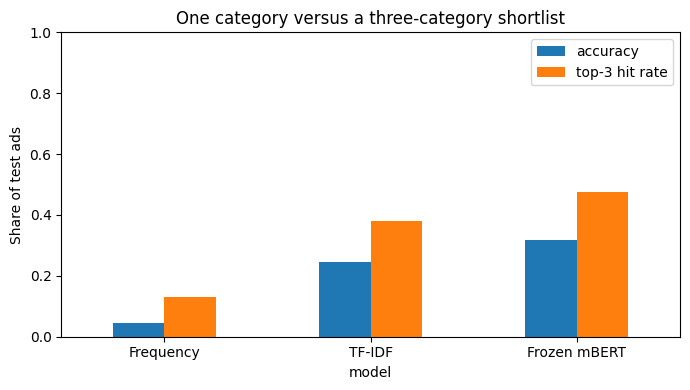

,teaching_id,category,predicted,top-3 suggestions,correct first suggestion
4246,JOB-04247,AUTOMATION_PROCESS_ENGINEERING,ELECTRICITY_ENGINEERING_INSTALLATION,ELECTRICITY_ENGINEERING_INSTALLATION | MAINTEN...,False
4247,JOB-04248,MANUFACTURING_PRODUCTION_INDUSTRY,PHARMACEUTICAL_R_D_ANALYSIS_PRODUCTION,PHARMACEUTICAL_R_D_ANALYSIS_PRODUCTION | SOFTW...,False
4248,JOB-04249,ADMINISTRATION_MANAGEMENT,SERVICE_BAR,SERVICE_BAR | COOKING_CUISINE | ROOM_SERVICE_C...,False
4249,JOB-04250,LOGISTICS_SUPPLY_CHAIN,WOOD_CONSTRUCTION,WOOD_CONSTRUCTION | MANUFACTURING_PRODUCTION_I...,False
4252,JOB-04253,CONSTRUCTION_WORK_SCAFFOLDING_MACHINERY,MANUFACTURING_PRODUCTION_INDUSTRY,MANUFACTURING_PRODUCTION_INDUSTRY | MAINTENANC...,False
4253,JOB-04254,PROJECT_MANAGEMENT_ANALYSIS,SYSTEM_ENGINEERING,SYSTEM_ENGINEERING | ARCHITECTURE_TECHNICAL_DR...,False


BERT first-suggestion errors: 523


In [10]:
results[['accuracy', 'top-3 hit rate']].plot.bar(
    ylim=(0, 1), rot=0, figsize=(7, 4), ylabel='Share of test ads',
    title='One category versus a three-category shortlist')
plt.tight_layout()
plt.show()
prediction = test_predictions['Frozen mBERT']
decisions = parts['test'][['teaching_id', 'category']].copy()
decisions['predicted'] = prediction
decisions['top-3 suggestions'] = [' | '.join(row) for row in test_shortlists['Frozen mBERT']]
decisions['correct first suggestion'] = prediction == y_test
display(decisions.loc[~decisions['correct first suggestion']].head(6))
print('BERT first-suggestion errors:', int((prediction != y_test).sum()))

## Optional: Eine Vorhersage für ein maskiertes Token

Die folgende Ausgabe zeigt eine tatsächliche Vorhersage des vortrainierten Modells (Inferenz) und weder einen Trainingsschritt noch eine Vorhersage der Stellenkategorie.

Beim Training mit Masked Language Modeling (MLM) wäre das ursprüngliche Text-Token das Trainingsziel und nicht das Token mit der höchsten vorhergesagten Wahrscheinlichkeit.

In [11]:
masked = tokenizer('We are hiring a [MASK] engineer.', return_tensors='pt')
position = int((masked['input_ids'][0] == tokenizer.mask_token_id).nonzero()[0].item())
with torch.inference_mode():
    probabilities = encoder(**masked).logits[0, position].softmax(dim=-1)
top = probabilities.topk(5)
display(pd.DataFrame({'token': tokenizer.convert_ids_to_tokens(top.indices.tolist()),
                      'model probability': top.values.tolist()}))

,token,model probability
0,civil,0.158859
1,tech,0.080236
2,qualified,0.069392
3,professional,0.062910
4,mechanical,0.027307


## Zusammenfassung und geschäftliche Auswirkungen

Wähle den Modellierungsansatz anhand der Ergebnisse auf den Validierungsdaten aus, evaluiere anschliessend die festgelegten Modelle und untersuche, wie sich ihre Fehler auf die manuelle Überprüfung durch die Betreiber des Stellenanzeigen-Portals auswirken.

Der Vergleich unterschiedlicher Textrepräsentationen ist kein kontrolliertes Experiment, aus dem sich eindeutige Ursache-Wirkungs-Zusammenhänge ableiten lassen.

## Einschränkungen

Dieser Lehrdatensatz mit echten Stellenanzeigen wurde bereits bei der Entwicklung der Vorlesung verwendet. Er ist deshalb kein vollständig unabhängiger Forschungs-Benchmark.

Die Überprüfung auf Duplikate und widersprüchliche Kategorienzuordnungen wurde rückblickend über den gesamten Zeitraum durchgeführt. Beinahe identische Stellenanzeigen und wiederverwendete Vorlagen sind weiterhin enthalten.

Die Kategorien sind ungleich verteilt, und zwei Testanzeigen gehören zu Kategorien, die in den Trainingsdaten nicht vorkommen. In der Vorlesung wurden 757 von 765 Testbeschreibungen aufgrund der begrenzten Eingabelänge gekürzt.

Das einfache Mean Pooling der BERT-Vektoren erzeugt keine speziell für die Ähnlichkeitssuche trainierten Satz-Embeddings.

Ein Vergleich zwischen extern vortrainiertem BERT und TF-IDF, das ausschliesslich auf den Trainingsdaten basiert, erlaubt keine eindeutige Aussage darüber, welchen kausalen Einfluss die Modellarchitektur auf die Ergebnisse hat.

Unterschiedliche Softwareversionen können die gemessenen Ergebnisse verändern.

Vor einem produktiven Einsatz sollten die Nützlichkeit bei der manuellen Überprüfung, die Leistung auf zukünftigen Daten, der Datenschutz und mögliche Änderungen an der Kategoriestruktur untersucht werden.

## Weiterführende Übungen

- Untersuche eine falsche erste Kategorievorhersage: Ist die richtige Kategorie trotzdem unter den drei vorgeschlagenen Kategorien enthalten?

- Erkläre, warum die beiden Testanzeigen mit unbekannten Kategorien bei der Berechnung der Kennzahlen weiterhin im Nenner berücksichtigt werden müssen.

- Welche wichtigen Informationen könnten durch das Kürzen der Stellenbeschreibungen verloren gehen? Wie würdest du eine längere Eingabe testen, ohne die Modelleinstellungen anhand des Testdatensatzes auszuwählen?

- Schlage eine Evaluation mit Daten aus einem zukünftigen Zeitraum sowie eine Kennzahl zur Messung des manuellen Überprüfungsaufwands der Portalbetreiber vor.

## References

**Required reading:** BERT overview: https://huggingface.co/docs/transformers/model_doc/bert
**Instructor references:** Vaswani et al. (2017), *Attention Is All You Need*, https://arxiv.org/abs/1706.03762;
Devlin et al. (2019), *BERT*, https://aclanthology.org/N19-1423/;
Brown et al. (2020), *Language Models are Few-Shot Learners*, https://arxiv.org/abs/2005.14165.

**Dataset provenance and distribution:** [NLP data notes](../../../00_Data/nlp_data_readme.md). **Lecture reference:** `Slides_MSC_Data_Science_Week_08_EN.pdf`, page 37 (original real-data comparison).

### Jupyter notebook - footer info

Include your name, submission date and a short description of your changes when submitting.